# 04. Temperature IV diagnostics for M7 only

This exploratory notebook examines the nine combinations of **three MPS crime types** (all, violent, property) and **three timing windows** (current calendar year, previous calendar year, prior 12 completed months). Every regression uses M7 controls, LSOA fixed effects and year-quarter fixed effects on the same complete sample.

The baseline candidate instrument counts days whose daily maximum 2-metre temperature reaches **25°C** in the corresponding window. A sensitivity section below compares **20°C, 22°C, 25°C and 27°C** on the same sales and model. Source files are in `project_data/temperature/` ([Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)); the saved regression estimates are in `data/04_crime_iv_outputs/`. The 32 requested weather points map to only 21 distinct returned weather locations.

**Temperature is not a validated instrument.** Heat may directly affect housing demand, comfort, energy costs or sale timing. Current-year weather can include days after the sale. The first-stage and exogeneity diagnostics below cannot establish the exclusion restriction.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
sys.path.insert(0, str(ROOT))
OUT = ROOT/'data'/'04_crime_iv_outputs'
SOURCE = ROOT/'project_data'/'temperature'
RESULT = OUT/'temperature_m7_iv_results.csv'
# Set True to refit all nine M7 regressions; a missing result is always fitted.
RUN_MODELS = False
if RUN_MODELS or not RESULT.exists():
    from utils.temperature_iv_m7 import main
    main()
results = pd.read_csv(RESULT)
crimes = ['allcrime','violentcrime','propertycrime']
timings = ['annual','lagyear','prior12']
crime_labels = {'allcrime':'All crime','violentcrime':'Violent crime','propertycrime':'Property crime'}
timing_labels = {'annual':'Current year','lagyear':'Previous year','prior12':'Prior 12 months'}
assert len(results)==9 and results.model.eq('M7').all()
assert results[['crime','exposure']].drop_duplicates().shape[0]==9
display(results[['model','crime','exposure','N','lsoa_clusters','weather_cell_clusters','fixed_effects']])
print('Temperature source:',SOURCE)
print('M7 estimates:',RESULT)

Fitting annual / allcrime / M7
Fitting annual / violentcrime / M7
Fitting annual / propertycrime / M7
Fitting lagyear / allcrime / M7
Fitting lagyear / violentcrime / M7
Fitting lagyear / propertycrime / M7
Fitting prior12 / allcrime / M7
Fitting prior12 / violentcrime / M7
Fitting prior12 / propertycrime / M7
model         crime exposure      N  first_stage_F_weather_cell  partial_R2  wooldridge_exogeneity_p
   M7      allcrime   annual 338347                    2.632891    0.000767                 0.008909
   M7  violentcrime   annual 338347                    2.519246    0.000510                 0.008255
   M7 propertycrime   annual 338347                    1.291198    0.000304                 0.008948
   M7      allcrime  lagyear 338347                    2.649130    0.000753                 0.687268
   M7  violentcrime  lagyear 338347                   18.740158    0.002221                 0.690284
   M7 propertycrime  lagyear 338347                    0.184629    0.000067       

,model,crime,exposure,N,lsoa_clusters,weather_cell_clusters,fixed_effects
0,M7,allcrime,annual,338347,4647,21,lsoacode; yearquarter
1,M7,violentcrime,annual,338347,4647,21,lsoacode; yearquarter
2,M7,propertycrime,annual,338347,4647,21,lsoacode; yearquarter
3,M7,allcrime,lagyear,338347,4647,21,lsoacode; yearquarter
4,M7,violentcrime,lagyear,338347,4647,21,lsoacode; yearquarter
5,M7,propertycrime,lagyear,338347,4647,21,lsoacode; yearquarter
6,M7,allcrime,prior12,338347,4647,21,lsoacode; yearquarter
7,M7,violentcrime,prior12,338347,4647,21,lsoacode; yearquarter
8,M7,propertycrime,prior12,338347,4647,21,lsoacode; yearquarter


Temperature source: /home/rachmiel/he3027/project_data/temperature
M7 estimates: /home/rachmiel/he3027/data/04_crime_iv_outputs/temperature_m7_iv_results.csv


## M7 design and diagnostic questions

The endogenous regressor is `ln(1 + crime)`, with `ln(price)` as the outcome. The first stage predicts crime from hot-day counts and the M7 controls and fixed effects. The second stage estimates the price coefficient using the predicted crime component. Matched OLS and 2SLS use the same observations.

- **Relevance:** the first-stage coefficient, weather-cell-clustered Wald statistic and partial R² describe whether hot days predict crime after controls. A statistic ≥10 is only a rough screen, especially with 21 weather cells.
- **Exogeneity test:** the Wooldridge regression test has the null that crime is exogenous, **conditional on a valid instrument**. A p value below .05 rejects that null; it does not validate temperature.
- **Exclusion:** temperature must not affect prices except through crime. This cannot be tested with one instrument for one endogenous variable. The models remain exploratory.

,crime,exposure,N,first_stage_beta_per_hot_day,first_stage_se_weather_cell,first_stage_F_weather_cell,partial_R2,wooldridge_exogeneity_chi2,wooldridge_exogeneity_p,F_at_least_10,requires_IV_if_valid_instrument
0,allcrime,annual,338347,-0.00415,0.00256,2.63289,0.00077,6.84102,0.00891,False,Yes
1,violentcrime,annual,338347,-0.00623,0.00393,2.51925,0.00051,6.97720,0.00826,False,Yes
2,propertycrime,annual,338347,-0.00315,0.00277,1.29120,0.00030,6.83322,0.00895,False,Yes
3,allcrime,lagyear,338347,-0.00381,0.00234,2.64913,0.00075,0.16206,0.68727,False,No
4,violentcrime,lagyear,338347,-0.01276,0.00295,18.74016,0.00222,0.15878,0.69028,True,No
5,propertycrime,lagyear,338347,-0.00136,0.00316,0.18463,0.00007,0.16101,0.68823,False,No
6,allcrime,prior12,338347,-0.00118,0.00048,6.00736,0.00033,3.98216,0.04598,False,Yes
7,violentcrime,prior12,338347,-0.00365,0.00097,14.26610,0.00084,4.02687,0.04478,True,Yes
8,propertycrime,prior12,338347,-0.00043,0.00058,0.53018,0.00003,3.97858,0.04608,False,Yes


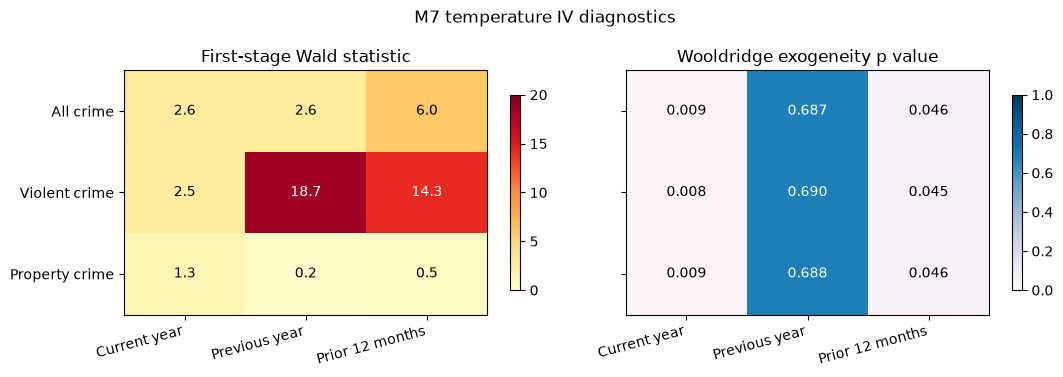

In [2]:
diagnostics=results[['crime','exposure','N','first_stage_beta_per_hot_day','first_stage_se_weather_cell','first_stage_F_weather_cell','partial_R2','wooldridge_exogeneity_chi2','wooldridge_exogeneity_p']].copy()
diagnostics['F_at_least_10']=diagnostics.first_stage_F_weather_cell.ge(10)
diagnostics['requires_IV_if_valid_instrument']=np.where(diagnostics.wooldridge_exogeneity_p.lt(.05),'Yes','No')
display(diagnostics.round(5))
diagnostics.to_csv(OUT/'temperature_m7_diagnostics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
for ax,column,title,cmap,vmin,vmax in [(axes[0],'first_stage_F_weather_cell','First-stage Wald statistic','YlOrRd',0,20),(axes[1],'wooldridge_exogeneity_p','Wooldridge exogeneity p value','PuBu',0,1)]:
    p=results.pivot(index='crime',columns='exposure',values=column).reindex(index=crimes,columns=timings)
    im=ax.imshow(p.to_numpy(),cmap=cmap,vmin=vmin,vmax=vmax,aspect='auto')
    for i in range(3):
        for j in range(3):
            v=p.iloc[i,j]
            ax.text(j,i,f'{v:.1f}' if column.startswith('first') else f'{v:.3f}',ha='center',va='center',fontsize=10,color='white' if (column.startswith('first') and v>13) or (not column.startswith('first') and v>.5) else 'black')
    ax.set_xticks(range(3),[timing_labels[t] for t in timings],rotation=15,ha='right')
    ax.set_yticks(range(3),[crime_labels[c] for c in crimes]); ax.set_title(title)
    fig.colorbar(im,ax=ax,shrink=.8)
fig.suptitle('M7 temperature IV diagnostics')
fig.tight_layout()
fig.savefig(OUT/'temperature_m7_diagnostics.png',dpi=170,bbox_inches='tight')
plt.show()

## Matched OLS and 2SLS estimates

Both estimates use the M7 sample and cluster standard errors by returned weather location (21 clusters). Large IV intervals accompany weak first stages. The full CSV also contains reduced-form estimates and 95% intervals. A difference between OLS and IV estimates is not a causal finding unless the instrument assumptions hold.

In [3]:
comparison=results[['crime','exposure','N','first_stage_F_weather_cell','ols_beta','ols_se','ols_p','iv_beta','iv_se','iv_p','iv_ci_low','iv_ci_high']].copy()
display(comparison.round(5))
comparison.to_csv(OUT/'temperature_m7_ols_vs_iv.csv',index=False)

,crime,exposure,N,first_stage_F_weather_cell,ols_beta,ols_se,ols_p,iv_beta,iv_se,iv_p,iv_ci_low,iv_ci_high
0,allcrime,annual,338347,2.63289,0.00572,0.00459,0.22730,-1.19378,0.88691,0.19336,-3.04384,0.65628
1,violentcrime,annual,338347,2.51925,0.00064,0.00333,0.85068,-0.79592,0.67202,0.25015,-2.19772,0.60588
2,propertycrime,annual,338347,1.29120,0.00739,0.00468,0.13001,-1.57649,1.46243,0.29387,-4.62707,1.47409
3,allcrime,lagyear,338347,2.64913,0.00077,0.00460,0.86926,-0.30036,0.79067,0.70803,-1.94968,1.34895
4,violentcrime,lagyear,338347,18.74016,-0.00086,0.00162,0.60370,-0.08964,0.23081,0.70185,-0.57111,0.39183
5,propertycrime,lagyear,338347,0.18463,0.00060,0.00427,0.88878,-0.84319,3.08767,0.78759,-7.28395,5.59757
6,allcrime,prior12,338347,6.00736,-0.00059,0.00427,0.89231,-0.89277,0.59963,0.15212,-2.14358,0.35803
7,violentcrime,prior12,338347,14.26610,0.00021,0.00354,0.95234,-0.28931,0.15722,0.08063,-0.61726,0.03864
8,propertycrime,prior12,338347,0.53018,-0.00017,0.00371,0.96494,-2.48096,3.94134,0.53617,-10.70245,5.74053


## Focus: violent crime in the prior 12 months

This is the only M7 combination with a first-stage statistic above the rough threshold of 10 **and** a Wooldridge p value below .05. It was selected after screening nine M7 combinations, so a borderline test result should be treated cautiously. The 2SLS confidence interval includes zero; neither relevance nor the exogeneity test establishes temperature's exclusion restriction.

,Value
N,338347.000000
weather_cell_clusters,21.000000
first_stage_beta_per_hot_day,-0.003646
first_stage_se_weather_cell,0.000965
first_stage_F_weather_cell,14.266104
partial_R2,0.000836
reduced_form_beta_per_hot_day,0.001055
reduced_form_p,0.059572
ols_beta,0.000214
ols_se,0.003543


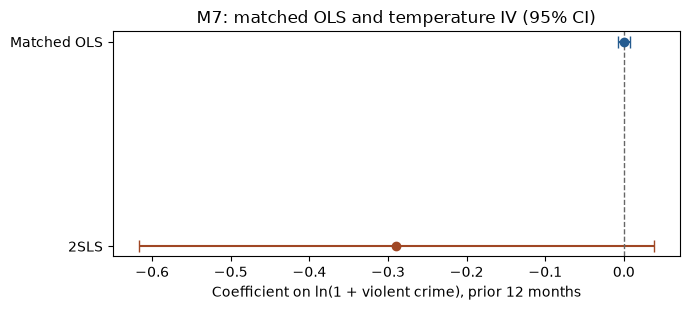

In [4]:
focus=results.loc[(results.crime=='violentcrime')&(results.exposure=='prior12')].copy()
assert len(focus)==1
focus.to_csv(OUT/'temperature_m7_violent_prior12_iv.csv',index=False)
r=focus.iloc[0]
display(focus[['N','weather_cell_clusters','first_stage_beta_per_hot_day','first_stage_se_weather_cell','first_stage_F_weather_cell','partial_R2','reduced_form_beta_per_hot_day','reduced_form_p','ols_beta','ols_se','ols_p','iv_beta','iv_se','iv_p','iv_ci_low','iv_ci_high','wooldridge_exogeneity_p']].T.rename(columns={focus.index[0]:'Value'}).round(6))
fig,ax=plt.subplots(figsize=(7,3.2))
for y,label,beta,low,high in [(1,'Matched OLS',r.ols_beta,r.ols_ci_low,r.ols_ci_high),(0,'2SLS',r.iv_beta,r.iv_ci_low,r.iv_ci_high)]:
    ax.errorbar(beta,y,xerr=[[beta-low],[high-beta]],fmt='o',capsize=4,color='#245b8f' if y else '#a04724')
ax.axvline(0,color='0.4',linestyle='--',linewidth=1)
ax.set_yticks([0,1],['2SLS','Matched OLS'])
ax.set_xlabel('Coefficient on ln(1 + violent crime), prior 12 months')
ax.set_title('M7: matched OLS and temperature IV (95% CI)')
fig.tight_layout()
fig.savefig(OUT/'temperature_m7_violent_prior12_ols_vs_iv.png',dpi=170,bbox_inches='tight')
plt.show()

## Temperature threshold sensitivity

The daily weather archive supports four cutoffs: 20°C (warm days), 22°C (upper-tail warmth), 25°C (baseline hot days), and 27°C (rare extreme heat). Each row retains the M7 controls, LSOA and year-quarter fixed effects, the same complete sale sample, and weather-cell-clustered uncertainty. Run `python -m utils.temperature_iv_thresholds` from the project root to regenerate the table, then `python -m utils.plot_temperature_iv_thresholds` to regenerate the figures. Comparing first-stage strength and IV stability across cutoffs is a sensitivity check, not an instrument-validity test.

![First-stage Wald F across thresholds](data/04_crime_iv_outputs/temperature_m7_threshold_first_stage.png)

![Prior12 violent-crime IV estimates across thresholds](data/04_crime_iv_outputs/temperature_m7_threshold_violent_prior12_iv.png)


In [ ]:
sensitivity_path = OUT / 'temperature_m7_threshold_sensitivity.csv'
sensitivity = pd.read_csv(sensitivity_path)
assert len(sensitivity) == 36 and sensitivity.groupby(['threshold_c', 'crime', 'exposure']).size().eq(1).all()
display(sensitivity[['threshold_c', 'crime', 'exposure', 'N', 'first_stage_beta_per_hot_day', 'first_stage_F_weather_cell', 'partial_R2', 'iv_beta', 'iv_ci_low', 'iv_ci_high']].round(4))

The threshold comparison does not support a stable IV result. At 22°C every weather-cell-clustered first-stage Wald F is below 3. At 27°C the all-crime prior12 first stage is effectively zero, producing an uninformative IV estimate. Violent-crime prior12 has F values of about 12.3, 2.4, 14.3 and 13.9 at 20°C, 22°C, 25°C and 27°C respectively; only the 27°C IV confidence interval excludes zero. This isolated result across 36 specifications is sensitive to the cutoff and does not address the exclusion restriction. With only 21 distinct weather-source clusters, inference is also fragile. These are exploratory diagnostics, not evidence that temperature identifies a causal crime effect.